# Issue #282 — conditional M×3 action-value policy

Executed prototype analysis. The independent unit is one Beijing issue. Action rows and 16 ticket streams are nested observations. The primary replay is frozen at 2022 year-end and applied to 2023; all 2024+ outcomes remain sealed.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
ROOT=Path.cwd()
while not (ROOT/'results/issue-282').exists() and ROOT != ROOT.parent: ROOT=ROOT.parent
R=ROOT/'results/issue-282'; F=ROOT/'docs/research/figures'; F.mkdir(parents=True,exist_ok=True)
decision=json.loads((R/'decision.json').read_text())
metrics=pd.read_csv(R/'policy_metrics_2023.csv')
baseline_selection=pd.read_csv(R/'development_fixed_baseline_selection.csv')
parameters=pd.read_csv(R/'parameter_performance_2023.csv')
yearly=pd.read_csv(R/'parameter_performance_by_year.csv')
predictions=pd.read_parquet(R/'predictions_2023.parquet')
ledger=pd.read_parquet(R/'deep_ensemble_ledger_2023.parquet')
oof=pd.read_csv(R/'expanding_oof_metrics.csv')
robustness=pd.read_csv(R/'static_action_robustness_2023.csv')
print(json.dumps(decision,indent=2)); display(baseline_selection); display(metrics)

{
  "contract": "BJ-UNIFIED-CONDITIONAL-POLICY-001/v1",
  "primary_replay": "FROZEN_AT_2022_YEAR_END_EXECUTED_ON_2023",
  "development_years": [
    2014,
    2022
  ],
  "test_year": 2023,
  "sealed_years_opened": [],
  "strongest_matched_fixed_baseline": "FIXED_N7_K8_TOP_MARKET",
  "baseline_selected_using": "2014_2022_DEVELOPMENT_TOTAL_PNL_BEFORE_2023",
  "deep_positive_brier_all_nested_action_rows": 0.13244060569692628,
  "positive_model_seed_count_vs_cash": 0,
  "funded_model_deviation_issues": 0,
  "holdout_criteria": {
    "ending_capital_above_cash": false,
    "ending_capital_above_frozen_active_baseline": true,
    "ex_largest_matched_lift_nonnegative": true,
    "max_drawdown_no_worse": true,
    "rolling10_worst_no_worse": true,
    "funded_model_deviation_issues_at_least_15": false,
    "largest_issue_positive_lift_share_at_most_half": true,
    "model_seeds_positive_vs_cash_at_least_3_of_5": false,
    "calibration_gate_preregistered_and_passed": false,
    "causal_and_se

,action_key,development_turnover_cny,development_pnl_cny,development_return_per_cny
0,SALL_OMARKET_N7_TOP_VALUE_K8,9072.0,3496.396355,0.385405
1,SALL_OVALUE_N7_WEIGHTED_WOR_K8,9072.0,-1386.481163,-0.152831
2,SALL_OVALUE_N7_WEIGHTED_WR_K8,9072.0,-1386.481163,-0.152831
3,SALL_OVALUE_N7_TOP_VALUE_K8,9072.0,-3844.146397,-0.423737
4,SALL_ODIVVALUE_N7_TOP_VALUE_K8,9072.0,-6799.055271,-0.749455


,policy,issues,ending_capital_cny,total_pnl_cny,turnover_cny,positive_issues,bet_issues,max_drawdown_fraction,max_consecutive_losing_issues,max_recovery_issues,rolling_5_loss_probability,rolling_5_worst_pnl_cny,rolling_10_loss_probability,rolling_10_worst_pnl_cny,rolling_20_loss_probability,rolling_20_worst_pnl_cny,matched_lift_cny,ex_largest_matched_lift_cny,largest_issue_positive_lift_share,changed_action_issues
0,FIXED_N7_K8_TOP_CELL_VALUE,53,99152.000000,-848.000000,848.0,0,53,0.008480,53,53,1.000000,-80.000000,1.000000,-160.000000,1.000000,-320.000000,-567.686894,-567.686894,0.000000,53.0
1,FIXED_N7_K8_TOP_MARKET,53,99719.686894,-280.313106,848.0,2,53,0.007168,45,45,0.836735,-80.000000,0.818182,-160.000000,0.764706,-320.000000,NaN,NaN,NaN,NaN
2,FIXED_N7_K8_TOP_DIVERGENCE,53,100218.791425,218.791425,848.0,1,53,0.006560,41,42,0.897959,-80.000000,0.772727,-160.000000,0.647059,-320.000000,499.104531,-567.686894,1.000000,53.0
3,FIXED_N7_K8_WR_CELL_VALUE,53,100134.209180,134.209180,848.0,8,53,0.003631,22,31,0.530612,-80.000000,0.363636,-160.000000,0.441176,-320.000000,414.522286,173.446964,0.250714,53.0
4,FIXED_N7_K8_WOR_CELL_VALUE,53,100134.209180,134.209180,848.0,8,53,0.003631,22,31,0.530612,-80.000000,0.363636,-160.000000,0.441176,-320.000000,414.522286,173.446964,0.250714,53.0
5,CASH_NO_BET,53,100000.000000,0.000000,0.0,0,0,-0.000000,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,280.313106,264.313106,0.019608,53.0
6,LINEAR,53,97616.173383,-2383.826617,8192.0,0,8,0.023838,2,25,0.428571,-1176.716121,0.568182,-1759.968651,0.735294,-2098.458003,-2103.513511,-2119.513511,0.023256,53.0
7,HGB,53,99289.972438,-710.027562,3072.0,4,15,0.007100,3,47,0.571429,-391.167988,0.750000,-401.995743,0.882353,-550.938170,-429.714456,-754.157931,0.267334,53.0
8,DEEP_ENSEMBLE,53,100000.000000,0.000000,0.0,0,0,-0.000000,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,280.313106,264.313106,0.019608,53.0
9,DEEP_SEED_282101,53,100000.000000,0.000000,0.0,0,0,-0.000000,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,280.313106,264.313106,0.019608,53.0


## Frozen baseline ladder

The fallback control is selected using only 2014–2022 total P&L. The table below is development evidence; no 2023 row participates in baseline selection.

,action_key,development_turnover_cny,development_pnl_cny,development_return_per_cny
0,SALL_OMARKET_N7_TOP_VALUE_K8,9072.0,3496.396355,0.385405
1,SALL_OVALUE_N7_WEIGHTED_WOR_K8,9072.0,-1386.481163,-0.152831
2,SALL_OVALUE_N7_WEIGHTED_WR_K8,9072.0,-1386.481163,-0.152831
3,SALL_OVALUE_N7_TOP_VALUE_K8,9072.0,-3844.146397,-0.423737
4,SALL_ODIVVALUE_N7_TOP_VALUE_K8,9072.0,-6799.055271,-0.749455


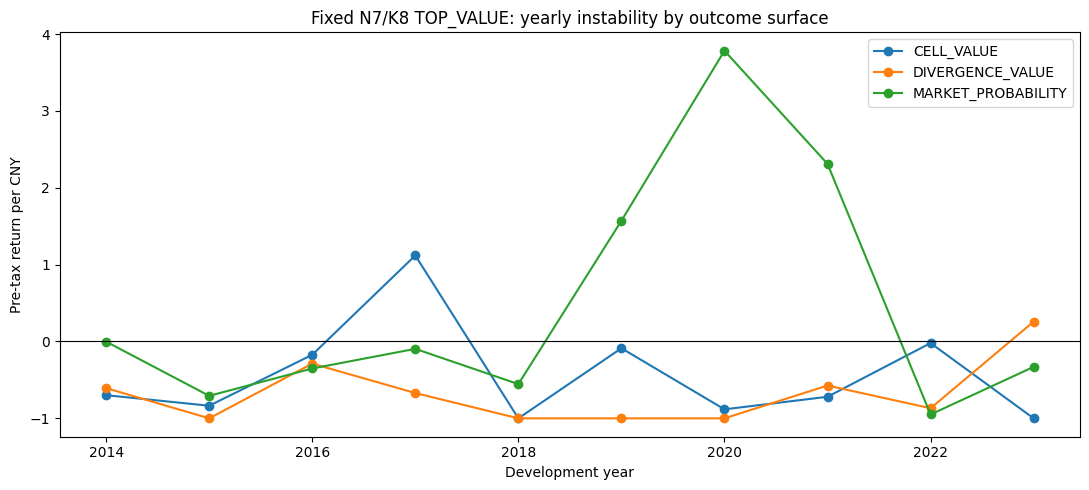

In [2]:
display(baseline_selection.sort_values('development_pnl_cny',ascending=False))
fixed=yearly[(yearly.selector=='ALL')&(yearly.n==7)&(yearly.k==8)&(yearly.generator=='TOP_VALUE')]
fig,ax=plt.subplots(figsize=(11,5))
for mode,g in fixed.groupby('outcome_weight_mode'):
    ax.plot(g.issue_year,g.return_per_cny,marker='o',label=mode)
ax.axhline(0,color='black',lw=.8); ax.set_xlabel('Development year'); ax.set_ylabel('Pre-tax return per CNY')
ax.set_title('Fixed N7/K8 TOP_VALUE: yearly instability by outcome surface'); ax.legend()
plt.tight_layout(); plt.savefig(F/'bj282_fixed_baseline_years.png',dpi=170); plt.show()

## Frozen-2022 2023 capital paths

Capital starts at CNY100,000. The learned policies use a prediction-only guard: deviate only if the candidate lower-confidence score beats both the frozen control and cash.

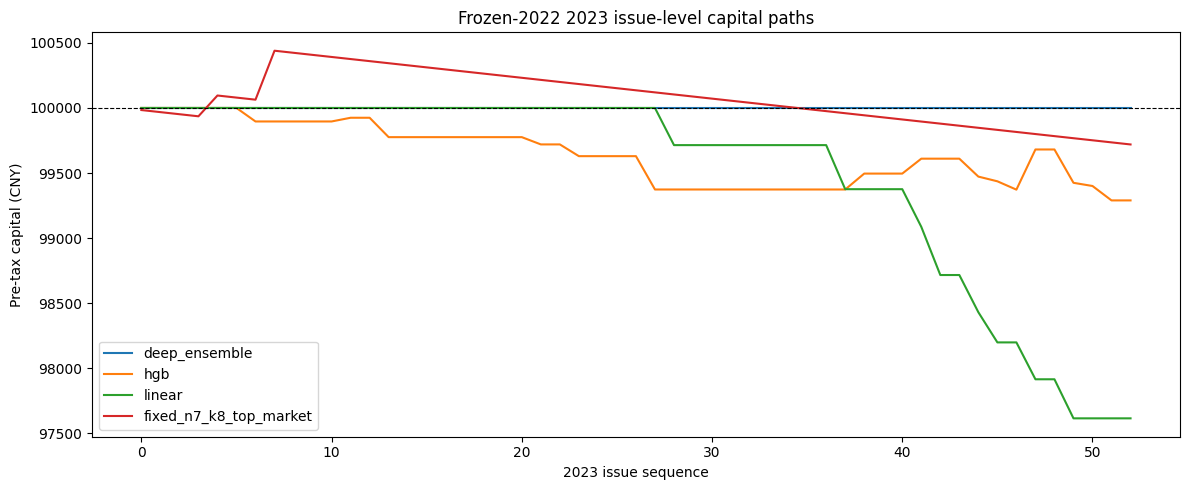

In [3]:
fig,ax=plt.subplots(figsize=(12,5))
for policy in ['deep_ensemble','hgb','linear',decision['strongest_matched_fixed_baseline'].lower()]:
    path=R/f'capital_path_{policy}.csv'
    if path.exists():
        d=pd.read_csv(path,dtype={'issue':str}); ax.plot(d.capital_cny,label=policy)
ax.axhline(100000,color='black',ls='--',lw=.8); ax.set_xlabel('2023 issue sequence'); ax.set_ylabel('Pre-tax capital (CNY)')
ax.set_title('Frozen-2022 2023 issue-level capital paths'); ax.legend()
plt.tight_layout(); plt.savefig(F/'bj282_2023_capital_paths.png',dpi=170); plt.show()

## Expanding-window out-of-fold check

Each validation year is predicted by models fitted only on earlier years. This separates a genuinely learned dynamic policy from a single favorable 2023 path. Cash/fallback decisions do not count as model deviations.

,validation_year,policy,fallback_name,development_end_year,funded_model_deviations,issues,ending_capital_cny,total_pnl_cny,turnover_cny,positive_issues,...,rolling_5_loss_probability,rolling_5_worst_pnl_cny,rolling_10_loss_probability,rolling_10_worst_pnl_cny,rolling_20_loss_probability,rolling_20_worst_pnl_cny,matched_lift_cny,ex_largest_matched_lift_cny,largest_issue_positive_lift_share,changed_action_issues
0,2018,LINEAR,FIXED_N7_K8_WOR_CELL_VALUE,2017,29,59,91237.354899,-8762.645101,29696.000,1,...,0.981818,-2276.538368,1.000000,-3322.667803,1.000000,-4807.106890,-8017.270619,-8089.648045,0.134937,59
1,2018,HGB,FIXED_N7_K8_WOR_CELL_VALUE,2017,17,59,98819.393219,-1180.606781,4128.000,6,...,0.600000,-762.473734,0.900000,-798.281913,0.975000,-880.235910,-435.232299,-634.712864,0.139627,58
2,2018,DEEP,FIXED_N7_K8_WOR_CELL_VALUE,2017,0,59,100000.000000,0.000000,0.000,0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,745.374482,729.374482,0.017544,59
3,2019,LINEAR,FIXED_N7_K8_WOR_CELL_VALUE,2018,14,53,96053.685777,-3946.314223,14336.000,0,...,0.734694,-1191.305055,0.931818,-1595.249404,1.000000,-2692.635329,-3436.997862,-3452.997862,0.027027,53
4,2019,HGB,FIXED_N7_K8_WOR_CELL_VALUE,2018,11,53,100141.276856,141.276856,2336.000,6,...,0.326531,-272.000000,0.363636,-528.000000,0.264706,-572.553011,650.593218,346.021173,0.170555,53
5,2019,DEEP,FIXED_N7_K8_WOR_CELL_VALUE,2018,0,53,100000.000000,0.000000,0.000,0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,509.316361,493.316361,0.020408,53
6,2020,LINEAR,FIXED_N7_K8_TOP_MARKET,2019,4,38,98920.156008,-1079.843992,4096.000,0,...,0.294118,-853.738474,0.517241,-853.738474,1.000000,-853.738474,-3379.997733,-3395.997733,0.029412,38
7,2020,HGB,FIXED_N7_K8_TOP_MARKET,2019,8,38,100515.661482,515.661482,1280.000,5,...,0.411765,-252.467565,0.413793,-252.467565,0.105263,-158.322670,-1784.492258,-1889.472569,0.158582,38
8,2020,DEEP,FIXED_N7_K8_TOP_MARKET,2019,2,38,100038.094395,38.094395,1509.875,1,...,0.029412,-148.400260,0.034483,-148.400260,0.052632,-148.400260,-2262.059345,-2464.554000,0.277202,38
9,2021,LINEAR,FIXED_N7_K8_TOP_MARKET,2020,17,63,95378.243870,-4621.756130,17408.000,0,...,0.745763,-1060.085937,0.925926,-1765.904152,1.000000,-2715.142836,-6950.905021,-6966.905021,0.024390,63


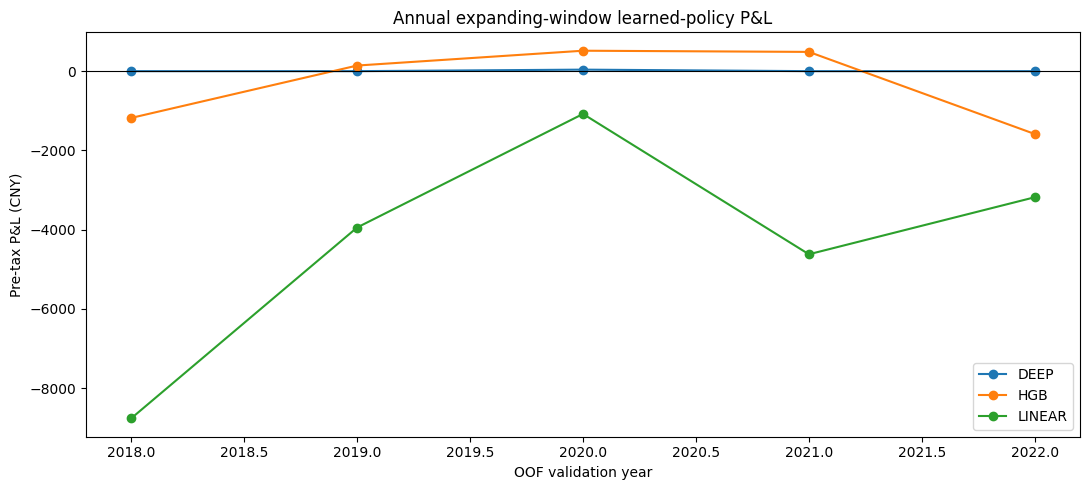

,total_pnl,funded_deviations,positive_years
policy,,,
DEEP,38.094395,2,1
HGB,-1625.025476,99,3
LINEAR,-21592.889054,75,0


In [4]:
display(oof)
fig,ax=plt.subplots(figsize=(11,5))
for policy,g in oof.groupby('policy'):
    ax.plot(g.validation_year,g.total_pnl_cny,marker='o',label=policy)
ax.axhline(0,color='black',lw=.8); ax.set(xlabel='OOF validation year',ylabel='Pre-tax P&L (CNY)',title='Annual expanding-window learned-policy P&L'); ax.legend()
plt.tight_layout(); plt.savefig(F/'bj282_expanding_oof.png',dpi=170); plt.show()
display(oof.groupby('policy').agg(total_pnl=('total_pnl_cny','sum'),funded_deviations=('funded_model_deviations','sum'),positive_years=('total_pnl_cny',lambda x:int((x>0).sum()))))

## Parameter-performance surface

These are fixed-policy 2023 slices, not independently validated discoveries. They reveal where selector, outcome direction, N, generator and K interact before the learned policy chooses among them.

,outcome_weight_mode,n,turnover,pnl,return_per_cny
0,CELL_VALUE,3,432480.0,-114238.291546,-0.264147
1,CELL_VALUE,4,432480.0,-111092.437988,-0.256873
2,CELL_VALUE,5,432480.0,-109437.851347,-0.253047
3,CELL_VALUE,6,432480.0,-105416.611128,-0.243749
4,CELL_VALUE,7,432480.0,-106782.338086,-0.246907
5,CELL_VALUE,8,432480.0,-87356.872445,-0.201991
6,DIVERGENCE_VALUE,3,432480.0,-129066.998503,-0.298435
7,DIVERGENCE_VALUE,4,432480.0,-129449.148879,-0.299318
8,DIVERGENCE_VALUE,5,432480.0,-115588.897722,-0.267270
9,DIVERGENCE_VALUE,6,432480.0,-122388.576307,-0.282992


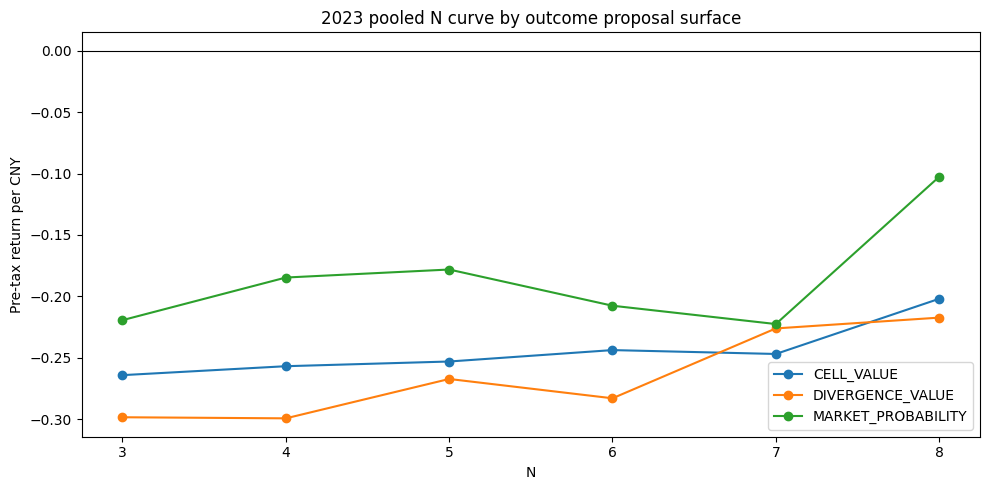

,selector,outcome_weight_mode,n,generator,k,issues,turnover_cny,pnl_cny,positive_issues,median_return_per_cny,return_per_cny
212,ALL,MARKET_PROBABILITY,8,WEIGHTED_WR,8,53,848.0,2427.032089,3,-1.000000,2.862066
208,ALL,MARKET_PROBABILITY,8,WEIGHTED_WOR,8,53,848.0,2427.032089,3,-1.000000,2.862066
209,ALL,MARKET_PROBABILITY,8,WEIGHTED_WOR,32,53,3392.0,4015.359011,10,-1.000000,1.183773
213,ALL,MARKET_PROBABILITY,8,WEIGHTED_WR,32,53,3392.0,4015.359011,10,-1.000000,1.183773
416,TOP_HALF_VALUE,MARKET_PROBABILITY,7,WEIGHTED_WR,8,53,848.0,617.374698,7,-1.000000,0.728036
412,TOP_HALF_VALUE,MARKET_PROBABILITY,7,WEIGHTED_WOR,8,53,848.0,617.374698,7,-1.000000,0.728036
210,ALL,MARKET_PROBABILITY,8,WEIGHTED_WOR,128,53,13568.0,7760.626316,26,-0.055563,0.571980
214,ALL,MARKET_PROBABILITY,8,WEIGHTED_WR,128,53,13568.0,7760.626316,26,-0.055563,0.571980
196,ALL,MARKET_PROBABILITY,7,WEIGHTED_WOR,8,53,848.0,408.102236,5,-1.000000,0.481253
200,ALL,MARKET_PROBABILITY,7,WEIGHTED_WR,8,53,848.0,408.102236,5,-1.000000,0.481253


In [5]:
n_curve=(parameters.groupby(['outcome_weight_mode','n'],as_index=False)
         .agg(turnover=('turnover_cny','sum'),pnl=('pnl_cny','sum')))
n_curve['return_per_cny']=n_curve.pnl/n_curve.turnover
display(n_curve)
fig,ax=plt.subplots(figsize=(10,5))
for mode,g in n_curve.groupby('outcome_weight_mode'):
    ax.plot(g.n,g.return_per_cny,marker='o',label=mode)
ax.axhline(0,color='black',lw=.8); ax.set_xlabel('N'); ax.set_ylabel('Pre-tax return per CNY')
ax.set_title('2023 pooled N curve by outcome proposal surface'); ax.legend()
plt.tight_layout(); plt.savefig(F/'bj282_2023_n_surface.png',dpi=170); plt.show()
display(parameters.sort_values('return_per_cny',ascending=False).head(25))

## Post-outcome static-policy hypothesis scan

This table is diagnostic only. It ranks fixed actions on 2023 outcomes, then displays their untouched 2014–2022 history beside them. A positive 2023 row is not a frozen Edge when the same action loses over development years.

In [6]:
cols=['action_key','test_return_per_cny','test_pnl_cny','test_ex_largest_pnl_cny','test_positive_issues','development_return_per_cny','development_positive_years','development_worst_year_return']
display(robustness[cols].head(25))
candidate=robustness[robustness.action_key.eq('SALL_OMARKET_N8_WEIGHTED_WR_K128')]
display(candidate[cols])

,action_key,test_return_per_cny,test_pnl_cny,test_ex_largest_pnl_cny,test_positive_issues,development_return_per_cny,development_positive_years,development_worst_year_return
0,SALL_OVALUE_N8_WEIGHTED_WOR_K512,0.175613,9530.884799,4387.689939,23.0,0.028222,5,-0.275918
1,SALL_OVALUE_N8_WEIGHTED_WR_K512,0.175613,9530.884799,4387.689939,23.0,0.028222,5,-0.275918
2,SALL_OMARKET_N8_WEIGHTED_WOR_K128,0.571980,7760.626316,6457.143424,26.0,-0.058352,2,-0.553907
3,SALL_OMARKET_N8_WEIGHTED_WR_K128,0.571980,7760.626316,6457.143424,26.0,-0.058352,2,-0.553907
4,STOP50_OVALUE_N8_WEIGHTED_WOR_K128,0.306441,4157.791849,1324.928268,17.0,-0.066931,2,-0.436183
5,STOP50_OVALUE_N8_WEIGHTED_WR_K128,0.306441,4157.791849,1324.928268,17.0,-0.066931,2,-0.436183
6,SALL_OMARKET_N8_WEIGHTED_WOR_K32,1.183773,4015.359011,2701.221410,10.0,-0.083456,4,-0.781083
7,SALL_OMARKET_N8_WEIGHTED_WR_K32,1.183773,4015.359011,2701.221410,10.0,-0.083456,4,-0.781083
8,SALL_OMARKET_N8_WEIGHTED_WOR_K8,2.862066,2427.032089,1064.894488,3.0,-0.278314,2,-1.000000
9,SALL_OMARKET_N8_WEIGHTED_WR_K8,2.862066,2427.032089,1064.894488,3.0,-0.278314,2,-1.000000


,action_key,test_return_per_cny,test_pnl_cny,test_ex_largest_pnl_cny,test_positive_issues,development_return_per_cny,development_positive_years,development_worst_year_return
3,SALL_OMARKET_N8_WEIGHTED_WR_K128,0.57198,7760.626316,6457.143424,26.0,-0.058352,2,-0.553907


## Learned action path and issue attribution

Oracle regret is joined only after each frozen action and is diagnostic. It is never a feature, class label or fallback rule.

,issue,action_key,guard_reason,predicted_score,pnl_cny_mean,matched_lift_cny,oracle_regret_cny_diagnostic,matched_failure_attribution
0,22112,NO_BET,CASH_FALLBACK,-27.736339,0.0,16.000000,452.941974,NO_NEGATIVE_MATCHED_LIFT
1,22114,NO_BET,CASH_FALLBACK,-26.616134,0.0,16.000000,1362.137600,NO_NEGATIVE_MATCHED_LIFT
2,22123,NO_BET,CASH_FALLBACK,-30.119843,0.0,16.000000,1930.541355,NO_NEGATIVE_MATCHED_LIFT
3,22124,NO_BET,CASH_FALLBACK,-28.288293,0.0,16.000000,506.968020,NO_NEGATIVE_MATCHED_LIFT
4,22126,NO_BET,CASH_FALLBACK,-30.646955,0.0,-159.650542,9699.797393,JOINT_STAGE_CHANGE
5,23011,NO_BET,CASH_FALLBACK,-27.101556,0.0,16.000000,1437.434851,NO_NEGATIVE_MATCHED_LIFT
6,23012,NO_BET,CASH_FALLBACK,-31.598947,0.0,16.000000,1297.256769,NO_NEGATIVE_MATCHED_LIFT
7,23013,NO_BET,CASH_FALLBACK,-28.940693,0.0,-376.036352,17818.906438,JOINT_STAGE_CHANGE
8,23014,NO_BET,CASH_FALLBACK,-30.159711,0.0,16.000000,1728.872946,NO_NEGATIVE_MATCHED_LIFT
9,23021,NO_BET,CASH_FALLBACK,-29.128689,0.0,16.000000,2942.089897,NO_NEGATIVE_MATCHED_LIFT


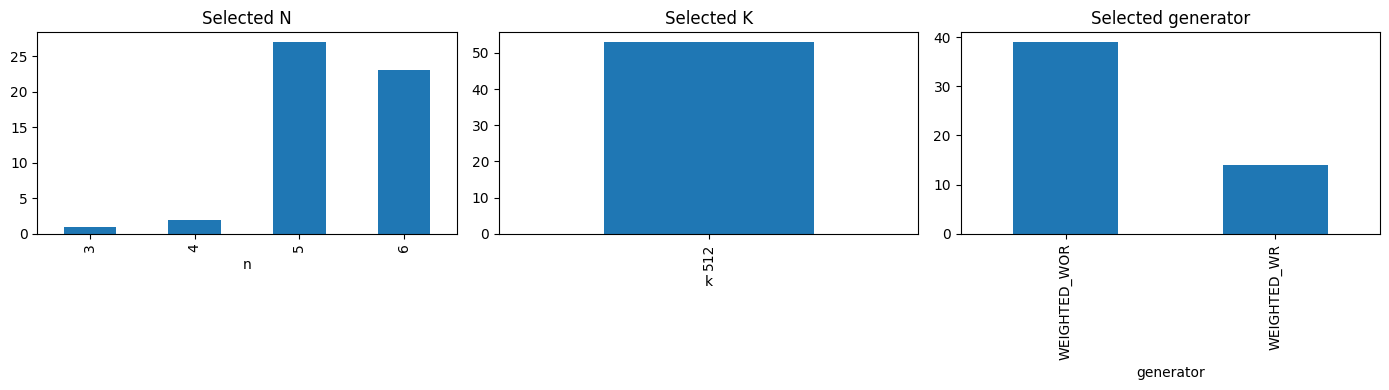

,issues
matched_failure_attribution,
NO_NEGATIVE_MATCHED_LIFT,51
JOINT_STAGE_CHANGE,2


In [7]:
display(ledger[['issue','action_key','guard_reason','predicted_score','pnl_cny_mean','matched_lift_cny','oracle_regret_cny_diagnostic','matched_failure_attribution']].head(25))
fig,axes=plt.subplots(1,3,figsize=(14,4))
ledger.n.value_counts().sort_index().plot.bar(ax=axes[0],title='Selected N')
ledger.k.value_counts().sort_index().plot.bar(ax=axes[1],title='Selected K')
ledger.generator.value_counts().plot.bar(ax=axes[2],title='Selected generator')
plt.tight_layout(); plt.savefig(F/'bj282_2023_selected_parameters.png',dpi=170); plt.show()
display(ledger.matched_failure_attribution.value_counts().rename('issues').to_frame())

## Distribution calibration

Because action rows within an issue are correlated, these plots diagnose model behavior but do not turn action rows into independent statistical evidence.

,probability_bin,predicted,observed,rows
0,"(0.00196, 0.0353]",0.020321,0.017467,2290
1,"(0.0353, 0.0567]",0.044866,0.027948,2290
2,"(0.0567, 0.0899]",0.074917,0.083879,2289
3,"(0.0899, 0.119]",0.102942,0.094323,2290
4,"(0.119, 0.17]",0.144669,0.171691,2289
5,"(0.17, 0.202]",0.186313,0.208734,2290
6,"(0.202, 0.233]",0.216594,0.228484,2289
7,"(0.233, 0.27]",0.251798,0.285590,2290
8,"(0.27, 0.3]",0.284818,0.298820,2289
9,"(0.3, 0.362]",0.318251,0.322271,2290


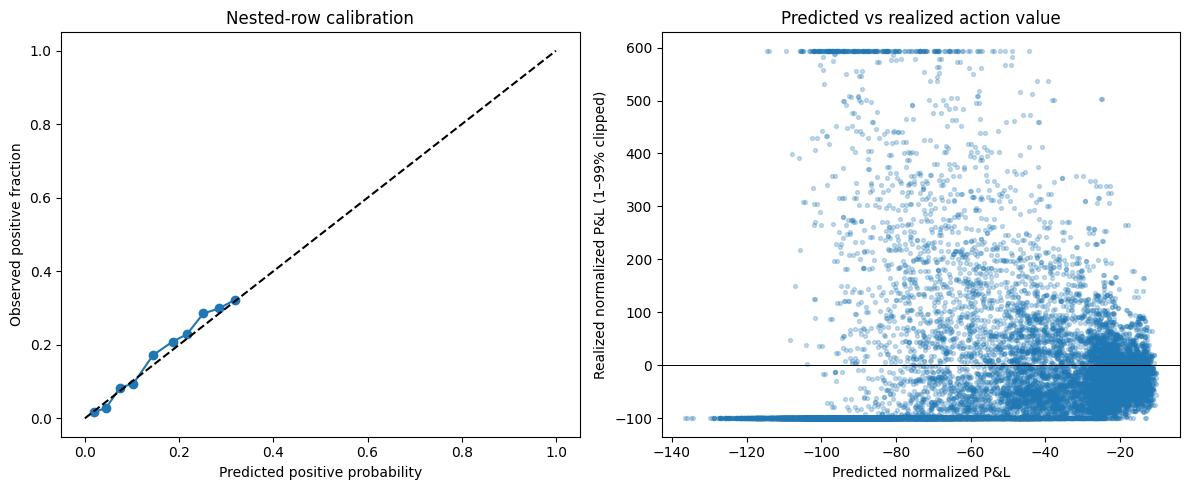

In [8]:
predictions['actual_positive']=predictions.normalized_pnl_cny100.gt(0)
predictions['probability_bin']=pd.qcut(predictions.deep_positive_probability_median,10,duplicates='drop')
cal=(predictions.groupby('probability_bin',observed=True)
     .agg(predicted=('deep_positive_probability_median','mean'),observed=('actual_positive','mean'),rows=('actual_positive','size')).reset_index())
display(cal)
fig,axes=plt.subplots(1,2,figsize=(12,5))
axes[0].plot(cal.predicted,cal.observed,marker='o'); axes[0].plot([0,1],[0,1],ls='--',color='black'); axes[0].set(xlabel='Predicted positive probability',ylabel='Observed positive fraction',title='Nested-row calibration')
lo,hi=predictions.normalized_pnl_cny100.quantile([.01,.99]); axes[1].scatter(predictions.deep_expected_value_median,predictions.normalized_pnl_cny100.clip(lo,hi),s=8,alpha=.25)
axes[1].axhline(0,color='black',lw=.7); axes[1].set(xlabel='Predicted normalized P&L',ylabel='Realized normalized P&L (1–99% clipped)',title='Predicted vs realized action value')
plt.tight_layout(); plt.savefig(F/'bj282_2023_calibration.png',dpi=170); plt.show()

## Decision reading

The decision JSON applies the preregistered holdout criteria jointly. A failed criterion is information about the current model and does not justify opening 2024+ outcomes. A positive-looking mean is challenged with ex-largest lift, seed dispersion, drawdown, rolling windows and action-support checks before any handoff.